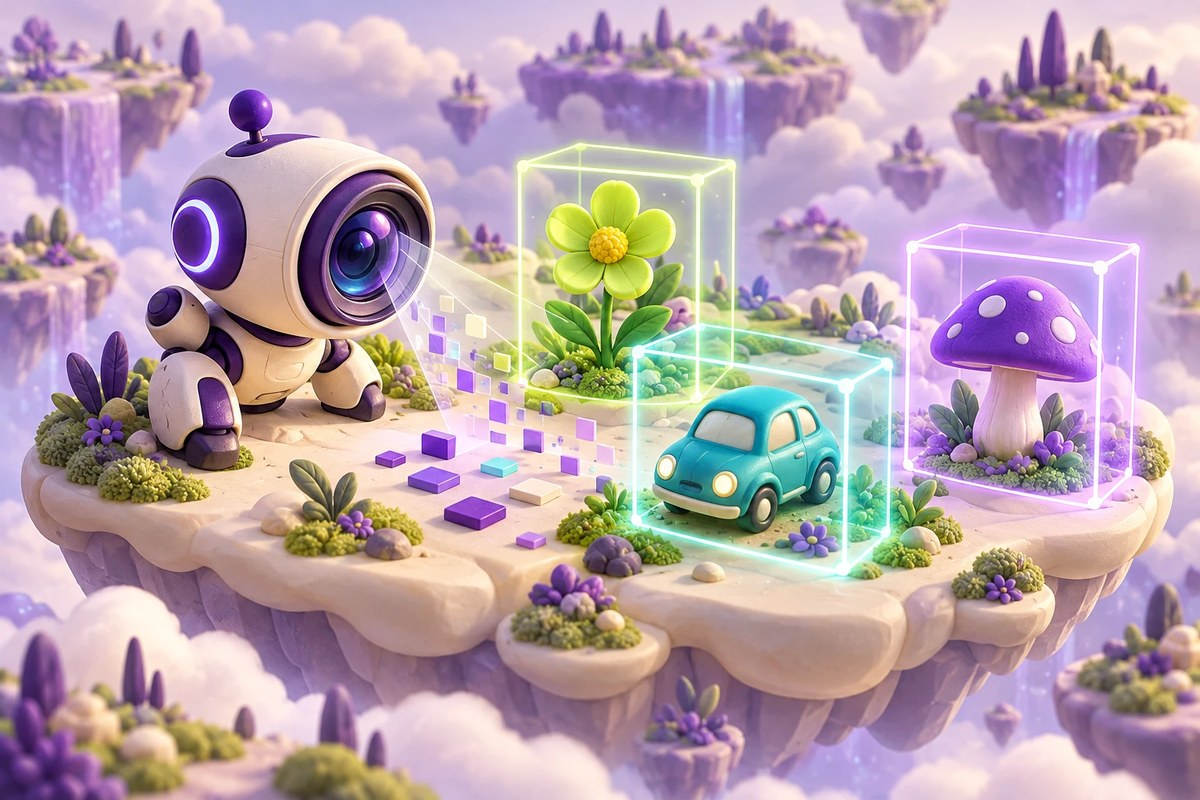

AI PATH · Компьютерное зрение · Урок 003

# Свёртка под микроскопом: Conv2D и Conv1D

Маленькие матрицы, заданные веса и проверка каждого вычисления

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-003-goal"></a>
## Что вы разберёте

Понять, как параметры свёртки меняют поле обзора, размер выхода и численное значение элемента.

### Перед началом

- Индексация многомерных массивов
- Скалярное произведение
- Формы входа и выхода слоя

### Что понадобится

- TensorFlow/Keras и NumPy
- Небольшие синтетические массивы создаются в самом ноутбуке
- Для блока groups проверьте поддержку channels_first выбранным вычислительным окружением

## Навигация по уроку

- [Цель и подготовка](#ai-003-goal)
- [Карта урока](#ai-003-map)
- [Задать контролируемый вход](#ai-003-section-01)
- [Изменить размер ядра](#ai-003-section-02)
- [Разобрать шаг и дополнение](#ai-003-section-03)
- [Расширить поле обзора](#ai-003-section-04)
- [Разделить каналы на группы](#ai-003-section-05)
- [Проверить активацию и смещение](#ai-003-section-06)
- [Прочитать настройки весов](#ai-003-section-07)
- [Перейти к Conv1D](#ai-003-section-08)
- [Проверьте понимание](#ai-003-practice)
- [Источники и ограничения](#ai-003-provenance)

<a id="ai-003-map"></a>
## Карта урока

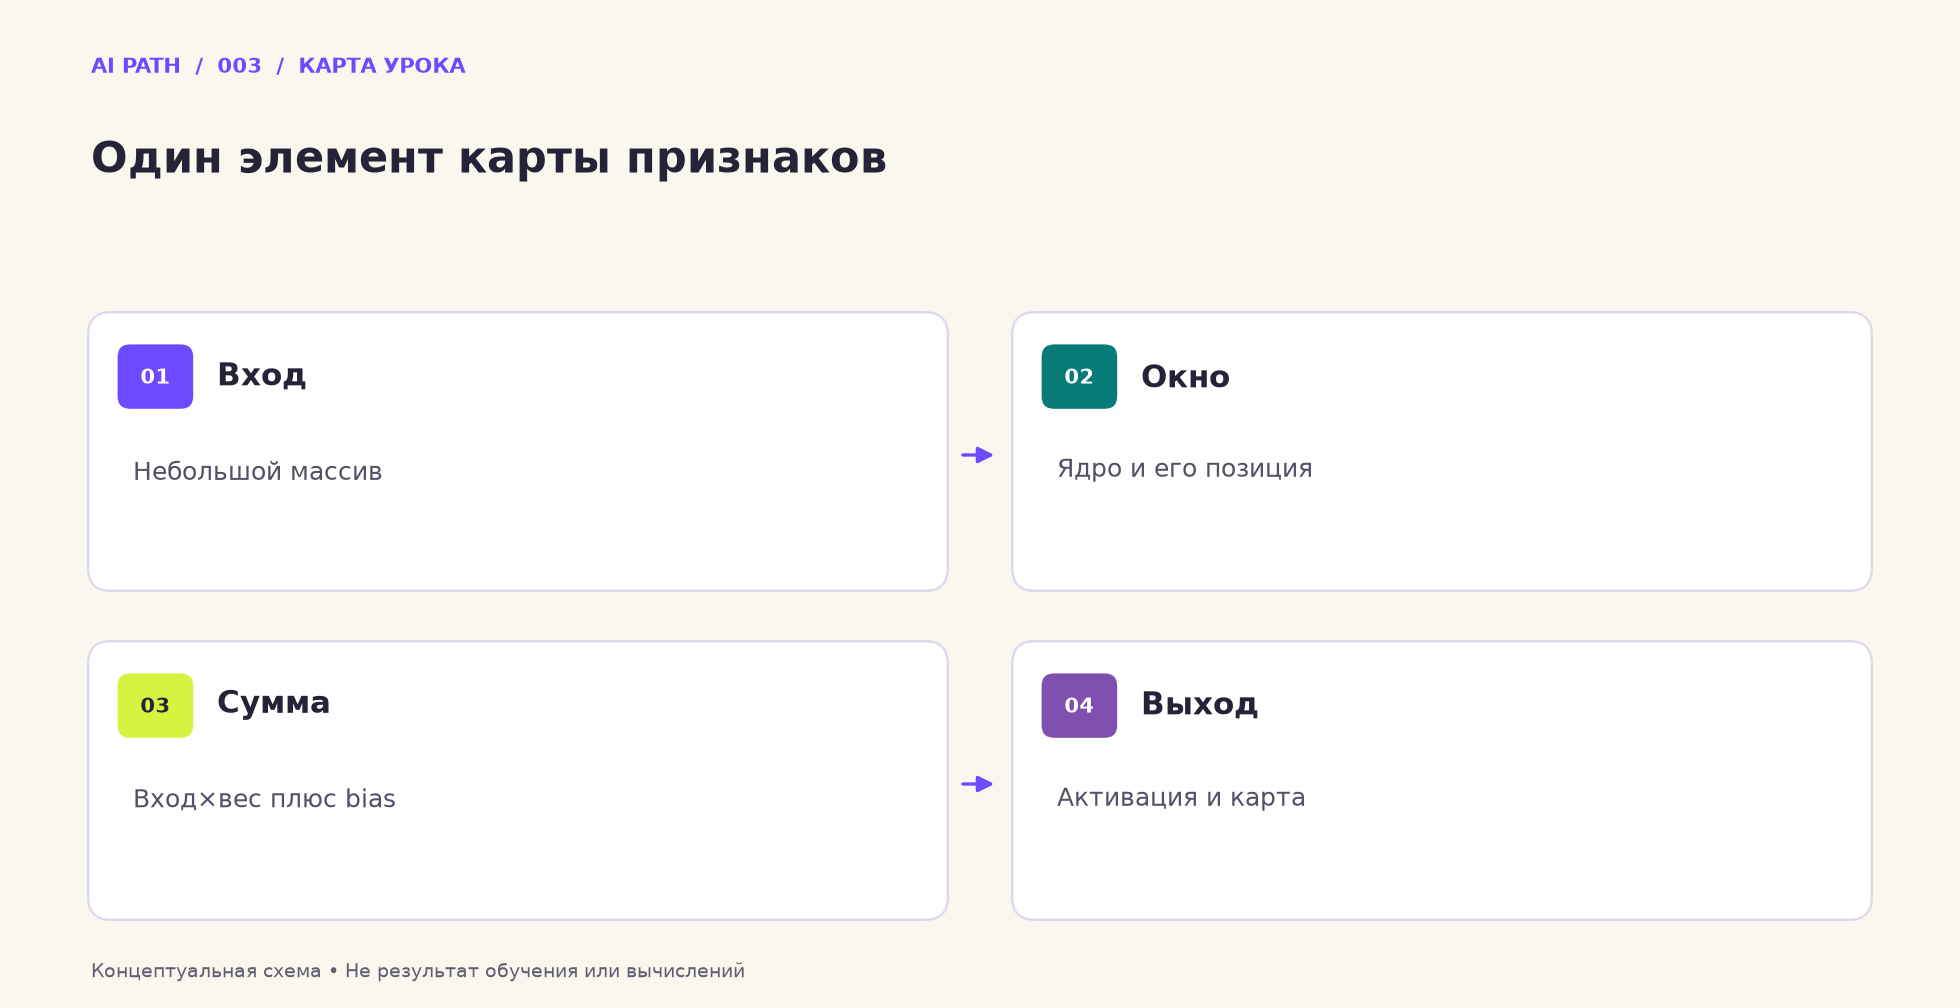

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Вход** — Небольшой массив
2. **Окно** — Ядро и его позиция
3. **Сумма** — Вход×вес плюс bias
4. **Выход** — Активация и карта

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/Conv2D_Arguments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-003-section-01"></a>
## 01 · Задать контролируемый вход

Массив 5×5 и вручную назначенные веса позволяют проверить вычисление без обучения и случайных данных.

_Далее — исходные ячейки учебного материала._

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Conv1D
import numpy as np
import tensorflow as tf

In [ ]:
inp = np.arange(1, 26)
inp = inp.reshape((5,5,1))
print(inp.squeeze())

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]


<a id="ai-003-section-02"></a>
## 02 · Изменить размер ядра

Для ядер 2×2, 3×3 и 4×4 сопоставьте результат predict с ручной суммой произведений.

_Далее — исходные ячейки учебного материала._

# filters and kernel_size

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
                kernel_size=(2,2),
                strides=(1, 1),
                padding="valid",
                data_format=None,
                dilation_rate=(1, 1),
                groups=1,
                activation=None,
                use_bias=False,
                kernel_initializer="glorot_uniform",
                bias_initializer="zeros",
                kernel_regularizer=None,
                bias_regularizer=None,
                activity_regularizer=None,
                kernel_constraint=None,
                bias_constraint=None,
                input_shape=(inp.shape)))
                # **kwargs   

model.compile()
model.summary()

Model: "sequential_44"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_27 (Conv2D)           (None, 4, 4, 1)           4         
Total params: 4
Trainable params: 4
Non-trainable params: 0
_________________________________________________________________


In [ ]:
custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0.]],
 
         [[1.]]],
 
 
        [[[2.]],
 
         [[3.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 4, 4, 1) 

[[ 35.  41.  47.  53.]
 [ 65.  71.  77.  83.]
 [ 95. 101. 107. 113.]
 [125. 131. 137. 143.]]


In [ ]:
2 + 6 *2 + 7*3

35

In [ ]:
7*0+8*1+12*2+13*3

71

## 3x3

In [ ]:
model = Sequential()
model.add(Conv2D(1, (3,3), use_bias=False, input_shape=inp.shape))
model.compile()

In [ ]:
custom_weights = np.array([[[[0]],[[1]],[[2]]],[[[3]],[[4]],[[5]]],[[[6]],[[7]],[[8]]]])
model.set_weights([custom_weights])

In [ ]:
model.get_weights()

[array([[[[0.]],
 
         [[1.]],
 
         [[2.]]],
 
 
        [[[3.]],
 
         [[4.]],
 
         [[5.]]],
 
 
        [[[6.]],
 
         [[7.]],
 
         [[8.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,1))
print(res.shape)

(1, 3, 3, 1)


In [ ]:
print(res[0].squeeze())

[[348. 384. 420.]
 [528. 564. 600.]
 [708. 744. 780.]]


## 4x4

In [ ]:
model = Sequential()
model.add(Conv2D(1, (4,4), use_bias=False, input_shape=inp.shape, padding='same'))
model.compile()

In [ ]:
custom_weights = np.array([[[[0]],[[1]],[[2]],[[3]]],[[[4]],[[5]],[[6]],[[7]]],[[[8]],[[9]],[[10]],[[11]]],[[[12]],[[13]],[[14]],[[15]]]])
model.set_weights([custom_weights])

In [ ]:
model.get_weights()

[array([[[[ 0.]],
 
         [[ 1.]],
 
         [[ 2.]],
 
         [[ 3.]]],
 
 
        [[[ 4.]],
 
         [[ 5.]],
 
         [[ 6.]],
 
         [[ 7.]]],
 
 
        [[[ 8.]],
 
         [[ 9.]],
 
         [[10.]],
 
         [[11.]]],
 
 
        [[[12.]],
 
         [[13.]],
 
         [[14.]],
 
         [[15.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,1))
print(res.shape)

(1, 5, 5, 1)


In [ ]:
print(res[0].squeeze())

[[ 756. 1030. 1144.  855.  566.]
 [1220. 1620. 1740. 1274.  826.]
 [1700. 2220. 2340. 1694. 1086.]
 [1044. 1330. 1396.  981.  608.]
 [ 502.  610.  638.  421.  241.]]


<a id="ai-003-section-03"></a>
## 03 · Разобрать шаг и дополнение

strides перемещает окно, а padding меняет обработку границ. До запуска предскажите размер выходной карты.

_Далее — исходные ячейки учебного материала._

# strides and padding

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
    kernel_size=(2,2),
    strides=(2,2),
    padding="same",
    data_format=None,
    dilation_rate=(1, 1),
    groups=1,
    activation=None,
    use_bias=False,
    kernel_initializer="glorot_uniform",
    bias_initializer="zeros",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    input_shape=(inp.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_50"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_33 (Conv2D)           (None, 3, 3, 1)           4         
Total params: 4
Trainable params: 4
Non-trainable params: 0
_________________________________________________________________


In [ ]:
custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0.]],
 
         [[1.]]],
 
 
        [[[2.]],
 
         [[3.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 3, 3, 1) 

[[ 35.  47.  20.]
 [ 95. 107.  40.]
 [ 22.  24.   0.]]


In [ ]:
2 + 6*2+ 7*3

35

In [ ]:
3*0+4*1+8*2+9*3

47

## 3x3

In [ ]:
model = Sequential()
model.add(Conv2D(1, (3,3), use_bias=False, padding="valid", input_shape=inp.shape))
model.compile()

In [ ]:
custom_weights = np.array([[[[0]],[[1]],[[2]]],[[[3]],[[4]],[[5]]],[[[6]],[[7]],[[8]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0.]],
 
         [[1.]],
 
         [[2.]]],
 
 
        [[[3.]],
 
         [[4.]],
 
         [[5.]]],
 
 
        [[[6.]],
 
         [[7.]],
 
         [[8.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 3, 3, 1) 

[[348. 384. 420.]
 [528. 564. 600.]
 [708. 744. 780.]]


In [ ]:
0*0 + 0*1 + 0*2 + 0*3 + 1*4 + 2*5 + 0*6 + 6*7 + 7*8

112

In [ ]:
19*0 + 20*1 + 24*3 +25*4

192

<a id="ai-003-section-04"></a>
## 04 · Расширить поле обзора

dilation_rate раздвигает позиции ядра без увеличения числа его коэффициентов.

_Далее — исходные ячейки учебного материала._

# dilation_rate

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
    kernel_size=(2,2),
    strides=(1, 1),
    padding="valid",
    data_format=None, # channels_last (default) or channels_first
    dilation_rate=(2, 2),
    groups=1,
    activation=None,
    use_bias=False,
    kernel_initializer="glorot_uniform",
    bias_initializer="zeros",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    input_shape=(inp.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_51"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_34 (Conv2D)           (None, 3, 3, 1)           4         
Total params: 4
Trainable params: 4
Non-trainable params: 0
_________________________________________________________________


In [ ]:
custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0.]],
 
         [[1.]]],
 
 
        [[[2.]],
 
         [[3.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 3, 3, 1) 

[[ 64.  70.  76.]
 [ 94. 100. 106.]
 [124. 130. 136.]]


In [ ]:
1*0 + 3*1 + 11*2 + 13*3

64

<a id="ai-003-section-05"></a>
## 05 · Разделить каналы на группы

В примере используются два входных канала и groups=2. Проверьте, какая группа входов связана с каждым выходом.

_Далее — исходные ячейки учебного материала._

# groups

In [ ]:
inp2 = np.concatenate([inp.squeeze(),inp.squeeze()],axis=0)
inp2 = inp2.reshape(2,5,5)
print(inp2.squeeze())

[[[ 1  2  3  4  5]
  [ 6  7  8  9 10]
  [11 12 13 14 15]
  [16 17 18 19 20]
  [21 22 23 24 25]]

 [[ 1  2  3  4  5]
  [ 6  7  8  9 10]
  [11 12 13 14 15]
  [16 17 18 19 20]
  [21 22 23 24 25]]]


In [ ]:
model = Sequential()
model.add(Conv2D(filters = 2,
    kernel_size=(2,2),
    strides=(1, 1),
    padding="valid",
    data_format='channels_first',
    dilation_rate=(1, 1),
    groups=2,
    activation=None,
    use_bias=False,
    kernel_initializer="glorot_uniform",
    bias_initializer="zeros",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    input_shape=(inp2.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_55"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_38 (Conv2D)           (None, 2, 4, 4)           8         
Total params: 8
Trainable params: 8
Non-trainable params: 0
_________________________________________________________________


In [ ]:
custom_weights = np.array([[[[0,0]],[[1,1]]],[[[2,2]],[[3,3]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0., 0.]],
 
         [[1., 1.]]],
 
 
        [[[2., 2.]],
 
         [[3., 3.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp2.reshape(1,2,5,5))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 2, 4, 4) 

[[[ 34.999996  40.999996  47.        52.999996]
  [ 65.        71.        76.99999   83.      ]
  [ 94.99999  101.       106.999985 112.99999 ]
  [124.999985 131.       137.       143.      ]]

 [[ 34.999996  40.999996  47.        52.999996]
  [ 65.        71.        76.99999   83.      ]
  [ 94.99999  101.       106.999985 112.99999 ]
  [124.999985 131.       137.       143.      ]]]


<a id="ai-003-section-06"></a>
## 06 · Проверить активацию и смещение

Отрицательные входы делают действие ReLU заметным. Затем отделите вклад bias от суммы свёртки.

_Далее — исходные ячейки учебного материала._

# activation

In [ ]:
inp_ = np.arange(-9, 16)
inp_ = inp_.reshape((5,5,1))
print(inp_.squeeze())

[[-9 -8 -7 -6 -5]
 [-4 -3 -2 -1  0]
 [ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]]


In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
    kernel_size=(2,2),
    strides=(1, 1),
    padding="valid",
    data_format=None,
    dilation_rate=(1, 1),
    groups=1,
    activation='relu',
    use_bias=False,
    kernel_initializer="glorot_uniform",
    bias_initializer="zeros",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    input_shape=(inp_.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_56"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_39 (Conv2D)           (None, 4, 4, 1)           4         
Total params: 4
Trainable params: 4
Non-trainable params: 0
_________________________________________________________________


In [ ]:
custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0.]],
 
         [[1.]]],
 
 
        [[[2.]],
 
         [[3.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp_.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 4, 4, 1) 

[[ 0.  0.  0.  0.]
 [ 5. 11. 17. 23.]
 [35. 41. 47. 53.]
 [65. 71. 77. 83.]]


In [ ]:
-9*0+-8*1+-4*2+-3*3

-25

In [ ]:
9*0+10*1+14*2+15*3

83

# use_bias

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
    kernel_size=(2,2),
    strides=(1, 1),
    padding="valid",
    data_format=None,
    dilation_rate=(1, 1),
    groups=1,
    activation=None,
    use_bias=True,
    kernel_initializer="glorot_uniform",
    bias_initializer="zeros",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    input_shape=(inp.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_57"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_40 (Conv2D)           (None, 4, 4, 1)           5         
Total params: 5
Trainable params: 5
Non-trainable params: 0
_________________________________________________________________


In [ ]:
# custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
# model.set_weights([custom_weights])
model.get_weights()

[array([[[[-0.5695899 ]],
 
         [[ 0.61981446]]],
 
 
        [[[ 0.02200526]],
 
         [[ 0.562964  ]]]], dtype=float32), array([0.], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 4, 4, 1) 

[[1.8111485 2.1593623 2.5075762 2.8557901]
 [3.5522177 3.9004316 4.2486453 4.5968595]
 [5.293287  5.641501  5.9897146 6.337929 ]
 [7.034356  7.3825703 7.730784  8.078998 ]]


<a id="ai-003-section-07"></a>
## 07 · Прочитать настройки весов

Инициализаторы задают начальные значения. Регуляризаторы и ограничения имеют другую роль, которую один прямой проход не демонстрирует полностью.

_Далее — исходные ячейки учебного материала._

# kernel_initializer and bias_initializer

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
    kernel_size=(2,2),
    strides=(1, 1),
    padding="valid",
    data_format=None,
    dilation_rate=(1, 1),
    groups=1,
    activation=None,
    use_bias=True,
    kernel_initializer="Ones", # RandomNormal, RandomUniform, TruncatedNormal, Glorot_uniform
                                         # Zeros, Ones, GlorotNormal, Identity, Orthogonal, 
                                         # Constant, VarianceScaling, custom
    bias_initializer="Ones",            
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    input_shape=(inp.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_60"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_43 (Conv2D)           (None, 4, 4, 1)           5         
Total params: 5
Trainable params: 5
Non-trainable params: 0
_________________________________________________________________


In [ ]:
# custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
# model.set_weights([custom_weights])
model.get_weights()

[array([[[[1.]],
 
         [[1.]]],
 
 
        [[[1.]],
 
         [[1.]]]], dtype=float32), array([1.], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 4, 4, 1) 

[[17. 21. 25. 29.]
 [37. 41. 45. 49.]
 [57. 61. 65. 69.]
 [77. 81. 85. 89.]]


In [ ]:
1 + 2 +6 + 7


16

# kernel_regularizer and bias_regularizer and activity_regularizer

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
                kernel_size=(2,2),
                strides=(1, 1),
                padding="valid",
                data_format=None,
                dilation_rate=(1, 1),
                groups=1,
                activation=None,
                use_bias=False,
                kernel_initializer="glorot_uniform",
                bias_initializer="zeros",
                kernel_regularizer=None,  # loss + среднее значение модулей весов ядра свертки * коэф
                bias_regularizer=None,    # loss
                activity_regularizer=None,# loss
                kernel_constraint=None,
                bias_constraint=None,
                input_shape=(inp.shape)))
                # **kwargs   

model.compile()
model.summary()

Model: "sequential_28"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_28 (Conv2D)           (None, 4, 4, 1)           4         
Total params: 4
Trainable params: 4
Non-trainable params: 0
_________________________________________________________________


In [ ]:
custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
model.set_weights([custom_weights])
model.get_weights()

[array([[[[0.]],
 
         [[1.]]],
 
 
        [[[2.]],
 
         [[3.]]]], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 4, 4, 1) 

[[ 35.  41.  47.  53.]
 [ 65.  71.  77.  83.]
 [ 95. 101. 107. 113.]
 [125. 131. 137. 143.]]


# bias_constraint

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 1,
    kernel_size=(2,2),
    strides=1,
    padding="valid",
    data_format=None,
    dilation_rate=(1, 1),
    groups=1,
    activation=None,
    use_bias=True,
    kernel_initializer="ones",
    bias_initializer="ones",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint='maxnorm',   # MaxNorm, MinMaxNorm, NonNeg, UnitNorm, RadialConstraint, custom
    input_shape=(inp.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_29"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_29 (Conv2D)           (None, 4, 4, 1)           5         
Total params: 5
Trainable params: 5
Non-trainable params: 0
_________________________________________________________________


In [ ]:
# custom_weights = np.array([[[[0]],[[1]]],[[[2]],[[3]]]])
# model.set_weights([custom_weights])
model.get_weights()

[array([[[[1.]],
 
         [[1.]]],
 
 
        [[[1.]],
 
         [[1.]]]], dtype=float32), array([1.], dtype=float32)]

In [ ]:
res = model.predict(inp.reshape(1,5,5,-1))
print(res.shape, '\n')
print(res[0].squeeze())

(1, 4, 4, 1) 

[[17. 21. 25. 29.]
 [37. 41. 45. 49.]
 [57. 61. 65. 69.]
 [77. 81. 85. 89.]]


<a id="ai-003-section-08"></a>
## 08 · Перейти к Conv1D

Последние примеры повторяют ручную проверку для последовательности и показывают влияние числа фильтров.

_Далее — исходные ячейки учебного материала._

# Сonv1D


In [ ]:
inp_1 = np.arange(1, 26)
inp_1 = inp_1.reshape((5,5))
print(inp_1.squeeze())

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]


In [ ]:
model = Sequential()
model.add(Conv1D(filters = 1,
    kernel_size=2,
    strides=1,
    padding="same",
    data_format=None,
    dilation_rate=1,
    groups=1,
    activation=None,
    use_bias=False,
    kernel_initializer="ones",
    bias_initializer="ones",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    input_shape=(inp_1.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_61"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv1d_15 (Conv1D)           (None, 5, 1)              10        
Total params: 10
Trainable params: 10
Non-trainable params: 0
_________________________________________________________________


In [ ]:
res = model.predict(inp_1[None,])
print(res.shape, '\n')
print(res[0])

(1, 5, 1) 

[[ 55.]
 [105.]
 [155.]
 [205.]
 [115.]]


In [ ]:
1 + 2 + 3 +4 +5 +6 +7 + 8 + 9 + 10

55

In [ ]:
6 + 7 + 8 + 9 + 10 + 11 + 12 + 13 + 14 + 15

105

In [ ]:
11 + 12 + 13 + 14 + 15 + 16 + 17 + 18 + 19 + 20

155

In [ ]:
model = Sequential()
model.add(Conv1D(filters = 2,
    kernel_size=2,
    strides=1,
    padding="same",
    data_format=None,
    dilation_rate=1,
    groups=1,
    activation=None,
    use_bias=False,
    kernel_initializer="ones",
    bias_initializer="ones",
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    input_shape=(inp_1.shape)))
    # **kwargs   

model.compile()
model.summary()

Model: "sequential_62"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv1d_16 (Conv1D)           (None, 5, 2)              20        
Total params: 20
Trainable params: 20
Non-trainable params: 0
_________________________________________________________________


In [ ]:
res = model.predict(inp_1[None,])
print(res.shape, '\n')
print(res[0])

(1, 5, 2) 

[[ 55.000008  55.000008]
 [104.999985 104.999985]
 [154.99997  154.99997 ]
 [204.99998  204.99998 ]
 [114.99998  114.99998 ]]


<a id="ai-003-practice"></a>
## Проверьте понимание

1. Вручную воспроизведите один элемент predict для ядра 2×2.
2. Рассчитайте форму выхода при same и valid с одним и тем же strides.
3. Объясните, почему constraint нельзя оценить только по предсказанию без обновления весов.

### Один самостоятельный эксперимент

Сохраните вход и веса ядра 2×2, а strides измените с 1 на 2; отдельно сравните same и valid.

**Критерий успеха:** Все формы предсказаны заранее, а хотя бы один граничный элемент проверен ручным вычислением.

<a id="ai-003-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/CV/Conv2D_Arguments.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Это разбор прямого прохода, а не обучение классификатора и не измерение качества модели.
- Блок channels_first/groups зависит от поддержки формата выбранной сборкой TensorFlow.
- В блоке regularizer передаются None, а constraint не сопровождается шагом оптимизатора; эффект регуляризации здесь не измерен.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.